In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, label_binarize
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from src.data import load_data, get_column_types, RISK_ORDER
from src.preprocessing import prepare_data, RANDOM_STATE
from src.models import train_models

In [2]:
X_train, X_test, y_train, y_test = prepare_data(load_data())
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1570, 15) | Test: (393, 15)


In [3]:
numeric, categorical = get_column_types(X_train)

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler())
    ]), numeric),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical)
])

counts = y_train.value_counts()
USE_SMOTE = counts.max() / counts.min() > 1.5

print("USE_SMOTE:", USE_SMOTE)

USE_SMOTE: False


In [4]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(random_state=RANDOM_STATE),
    "SVC": CalibratedClassifierCV(estimator=SVC(random_state=RANDOM_STATE),method="sigmoid",cv=5),
}

pipelines = {}

for name, model in models.items():
    steps = [("preprocessing", preprocessor)]

    if USE_SMOTE:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))

    steps.append(("model", model))

    pipelines[name] = ImbPipeline(steps).fit(X_train, y_train)

    print("trained:", name)

trained: LogisticRegression
trained: RandomForest
trained: SVC


In [5]:
rows = []

for name, pipe in pipelines.items():
    for split, X, y in [
        ("train", X_train, y_train),
        ("test", X_test, y_test)
    ]:
        pred = pipe.predict(X)
        proba = pipe.predict_proba(X)

        rows.append({
            "model": name,
            "split": split,
            "accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred, average="macro"),
            "recall": recall_score(y, pred, average="macro"),
            "f1": f1_score(y, pred, average="macro"),
            "roc_auc": roc_auc_score(
                y, proba, multi_class="ovr", average="macro"
            )
        })

metrics = pd.DataFrame(rows)

metrics[metrics["split"] == "test"].set_index("model").drop(
    columns="split"
).round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
LogisticRegression,0.784,0.783,0.783,0.783,0.922
RandomForest,0.720,0.713,0.719,0.714,0.872
SVC,0.740,0.731,0.739,0.731,0.889


In [6]:
pivot = metrics.pivot(index="model", columns="split", values="f1")
pivot["gap"] = pivot["train"] - pivot["test"]
pivot.round(3)

split,test,train,gap
model,,,
LogisticRegression,0.783,0.759,-0.024
RandomForest,0.714,1.000,0.286
SVC,0.731,0.833,0.102


In [7]:
for name, pipe in pipelines.items():
    print(name)
    print(classification_report(y_test, pipe.predict(X_test), target_names=RISK_ORDER, digits=3))

LogisticRegression
              precision    recall  f1-score   support

         Low      0.830     0.862     0.845       130
      Medium      0.669     0.674     0.672       129
        High      0.852     0.813     0.832       134

    accuracy                          0.784       393
   macro avg      0.783     0.783     0.783       393
weighted avg      0.784     0.784     0.784       393

RandomForest
              precision    recall  f1-score   support

         Low      0.764     0.823     0.793       130
      Medium      0.618     0.527     0.569       129
        High      0.755     0.806     0.780       134

    accuracy                          0.720       393
   macro avg      0.713     0.719     0.714       393
weighted avg      0.713     0.720     0.715       393

SVC
              precision    recall  f1-score   support

         Low      0.773     0.892     0.829       130
      Medium      0.629     0.512     0.564       129
        High      0.790     0.813     0

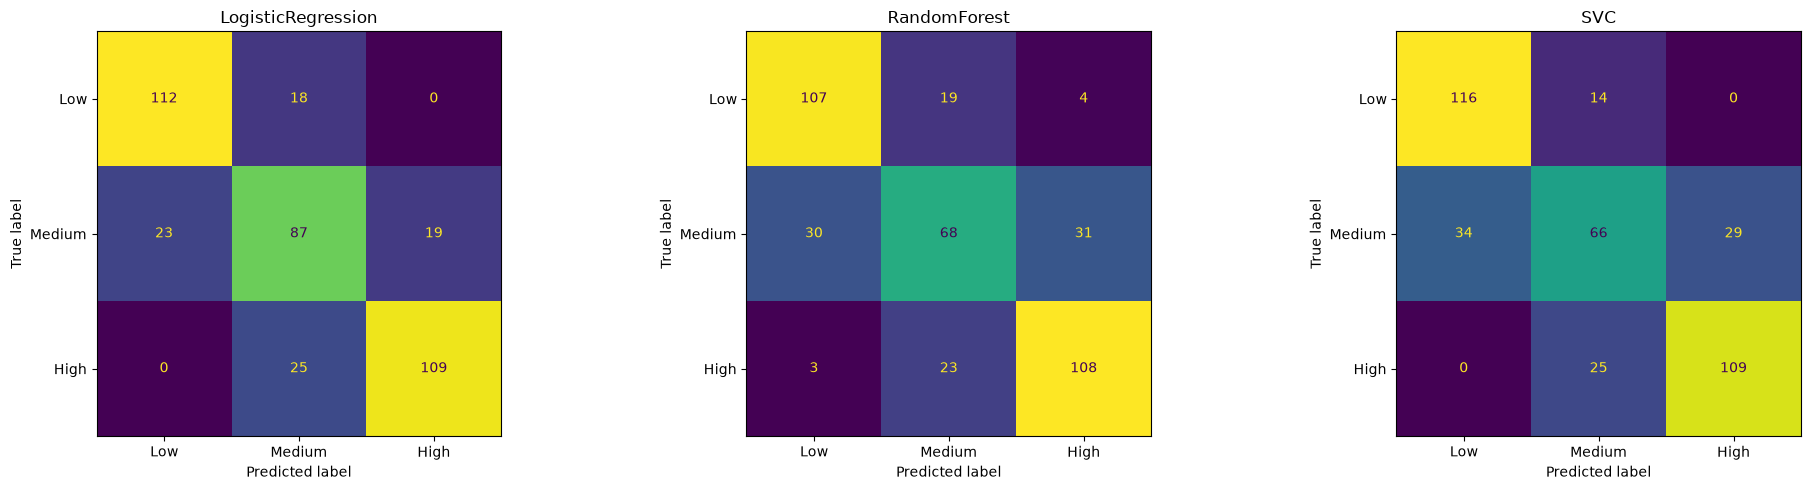

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, (name, pipe) in zip(axes, pipelines.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))

    ConfusionMatrixDisplay(
        cm, display_labels=RISK_ORDER
    ).plot(ax=ax, colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()

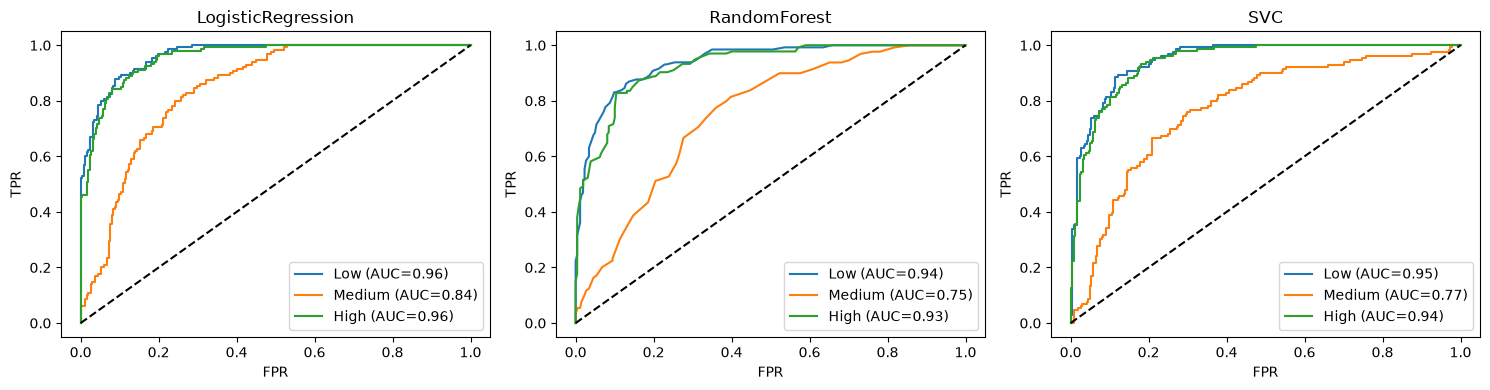

In [9]:
y_bin = label_binarize(y_test, classes=[0, 1, 2])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pipe) in zip(axes, pipelines.items()):
    proba = pipe.predict_proba(X_test)
    for i, risk in enumerate(RISK_ORDER):
        fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
        ax.plot(fpr, tpr, label=f"{risk} (AUC={roc_auc_score(y_bin[:, i], proba[:, i]):.2f})")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_title(name)
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.legend()
plt.tight_layout()
plt.show()

In [10]:
test = metrics[metrics.split == "test"].set_index("model").drop(columns="split")
test.sort_values("f1", ascending=False).round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
LogisticRegression,0.784,0.783,0.783,0.783,0.922
SVC,0.740,0.731,0.739,0.731,0.889
RandomForest,0.720,0.713,0.719,0.714,0.872
